# 02 · Stage 2 — cross-modal attention and modality-graph gated fusion: training, evaluation, robustness and figures

This is the notebook that produced every result reported in the article (Tables 6–9, Figures 6–8). Its code and saved outputs are unchanged from the original run (`P2_model_v6(Final).ipynb`); only these markdown cells and the environment cell below were added.

**What it does.** Loads the Stage-1 encoders (notebook 01) plus a dedicated OCT EfficientNet-B0 with ImageNet weights, encodes every sample once into four 512-d nodes (CFP, OCT, UWF, descriptor) with a validity mask, trains only the fusion head for 30 epochs, selects the checkpoint by validation F1 and the threshold on validation, scores the test split once, withholds each modality in turn, and summarises the gate weights.

**Split used here.** All 17,224 samples, 70/15/15, stratified, seed 42: train 12,056, validation 2,584, test 2,584. This split is drawn independently of the Stage-1 split of notebook 01, so 1,740 test samples and 1,697 validation samples were Stage-1 training samples (notebook 03). The reported results are therefore likely optimistic.

**Run history.** The saved outputs come from the last session of this notebook, in which the feature cache and the best checkpoint already existed on Drive, so cells 4 and 6 loaded them instead of recomputing (`Skipping … already cached`, `Best checkpoint already exists, skipping training`). Training had been run in an earlier session of the same code; its per-epoch log is `results/approved_fast_attention_gnn_history.csv` (best validation F1 0.9211 at epoch 3). Deleting the two files in `OUTPUT_DIR` reruns extraction and training.

**Inputs:** `DatasetRT/manifest.csv`, `DatasetRT/metadata.csv`, MMRDR images, `stage1_outputs/stage6_full_effnet_b0_best.pt`.  
**Outputs (`approved_fast_model_outputs/`):** see `results/` in this repository.

In [ ]:
# Added for reproducibility (not part of the original run): records the computing environment.
import platform, sys, os
import torch, sklearn, numpy as np, pandas as pd
try:
    import timm; timm_version = timm.__version__
except ImportError:
    timm_version = 'not installed yet (installed in the next cell)'
print('Python:', sys.version.split()[0], '| OS:', platform.platform(), '| CPU cores:', os.cpu_count())
try:
    import psutil; print('RAM (GB):', round(psutil.virtual_memory().total / 1e9, 1))
except ImportError:
    pass
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
print('torch', torch.__version__, '| timm', timm_version, '| scikit-learn', sklearn.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)

## Configuration
Paths, seed 42, image size 224, embedding width 512.

In [ ]:
!pip -q install timm

from google.colab import drive
drive.mount("/content/drive")

import os
from pathlib import Path
import random
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm
from PIL import Image
from tqdm.auto import tqdm

from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    classification_report
)

PROJECT_ROOT = Path("/content/drive/MyDrive/MMRDR_Project")
DATA_ROOT = PROJECT_ROOT / "DatasetRT"
OUTPUT_DIR = PROJECT_ROOT / "approved_fast_model_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

STAGE6_CKPT = PROJECT_ROOT / "stage1_outputs" / "stage6_full_effnet_b0_best.pt"
# v2: bumped so a real OCT encoder is used instead of the reused fundus encoder;
# forces cached features to be regenerated rather than reusing the stale v1 cache.
CACHE_PATH = OUTPUT_DIR / "approved_full_cached_features_v2.pt"

SEED = 42
IMAGE_SIZE = 224
EMB = 512
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Image decoding from the Drive-mounted dataset is I/O bound, not GPU bound
# (GPU sits idle waiting on disk reads). Parallel workers overlap Drive reads
# instead of loading one file at a time on the main process.
NUM_WORKERS = min(4, os.cpu_count() or 2)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)
print("NUM_WORKERS:", NUM_WORKERS)
print("DATA_ROOT:", DATA_ROOT.exists())
print("Stage6 checkpoint:", STAGE6_CKPT.exists())
print("Feature cache:", CACHE_PATH.exists())

Mounted at /content/drive
Device: cuda
NUM_WORKERS: 2
DATA_ROOT: True
Stage6 checkpoint: True
Feature cache: True


## Stage-2 split and descriptor preprocessing
All samples with at least one image are kept (17,224). Descriptor preprocessing is fitted on this notebook's training split (30 features).

In [ ]:
manifest = pd.read_csv(DATA_ROOT / "manifest.csv")
metadata = pd.read_csv(DATA_ROOT / "metadata.csv")

df = manifest.merge(metadata, on=["sample_id", "patient_id"], how="left")
df = df.dropna(subset=["dr_grade"]).copy()
df["dr_grade"] = df["dr_grade"].astype(int)
df["referable_dr"] = (df["dr_grade"] >= 2).astype(int)

df = df[
    df["fundus_path"].notna() |
    df["oct_path"].notna() |
    df["uwf_path"].notna()
].copy()

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["referable_dr"],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["referable_dr"],
)

print("Full usable dataset:", df.shape)
print("Train:", train_df.shape, train_df["referable_dr"].value_counts().sort_index().to_dict())
print("Val:", val_df.shape, val_df["referable_dr"].value_counts().sort_index().to_dict())
print("Test:", test_df.shape, test_df["referable_dr"].value_counts().sort_index().to_dict())

numeric_cols = [
    "age", "diabetes_duration", "hba1c", "systolic_bp", "diastolic_bp",
    "bmi", "visual_acuity", "intraocular_pressure", "metadata_is_synthetic"
]

categorical_cols = [
    "gender", "ethnicity", "diabetes_type", "hypertension", "hyperlipidemia",
    "kidney_disease", "smoking_status", "alcohol_status"
]

numeric_cols = [c for c in numeric_cols if c in train_df.columns]
categorical_cols = [c for c in categorical_cols if c in train_df.columns]

try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

metadata_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", onehot),
    ]), categorical_cols),
])

train_meta = metadata_preprocessor.fit_transform(train_df).astype(np.float32)
val_meta = metadata_preprocessor.transform(val_df).astype(np.float32)
test_meta = metadata_preprocessor.transform(test_df).astype(np.float32)

metadata_dim = train_meta.shape[1]
print("metadata_dim:", metadata_dim)

Full usable dataset: (17224, 32)
Train: (12056, 32) {0: 7671, 1: 4385}
Val: (2584, 32) {0: 1644, 1: 940}
Test: (2584, 32) {0: 1645, 1: 939}
metadata_dim: 30


## Feature extractor
CFP, UWF and descriptor encoders are loaded from the Stage-1 checkpoint. The 313 missing keys are the OCT backbone (kept with its ImageNet weights) and the OCT projection layer (kept at its random initialisation); the 10 unexpected keys are the Stage-1 gate and classifier, which are not used.

In [ ]:
class Stage6FeatureExtractor(nn.Module):
    def __init__(self, metadata_dim, backbone="tf_efficientnet_b0", emb=512):
        super().__init__()

        self.fundus_encoder = timm.create_model(backbone, pretrained=False, num_classes=0, global_pool="avg")
        self.uwf_encoder = timm.create_model(backbone, pretrained=False, num_classes=0, global_pool="avg")
        # Dedicated OCT branch (previously OCT images were routed through the fundus
        # encoder, which was never trained on OCT's cross-sectional appearance).
        # If the stage6 checkpoint contains real oct_encoder/oct_proj weights they will
        # be picked up by load_state_dict below; otherwise this falls back to ImageNet
        # weights, which is still a better starting point than a fundus-only encoder.
        self.oct_encoder = timm.create_model(backbone, pretrained=True, num_classes=0, global_pool="avg")

        image_dim = self.fundus_encoder.num_features

        self.fundus_proj = nn.Sequential(
            nn.Linear(image_dim, emb), nn.LayerNorm(emb), nn.GELU(), nn.Dropout(0.30)
        )

        self.uwf_proj = nn.Sequential(
            nn.Linear(image_dim, emb), nn.LayerNorm(emb), nn.GELU(), nn.Dropout(0.30)
        )

        self.oct_proj = nn.Sequential(
            nn.Linear(image_dim, emb), nn.LayerNorm(emb), nn.GELU(), nn.Dropout(0.30)
        )

        self.metadata_encoder = nn.Sequential(
            nn.Linear(metadata_dim, 256), nn.LayerNorm(256), nn.GELU(), nn.Dropout(0.25),
            nn.Linear(256, emb), nn.LayerNorm(emb), nn.GELU()
        )

    def encode_fundus(self, x):
        return self.fundus_proj(self.fundus_encoder(x))

    def encode_uwf(self, x):
        return self.uwf_proj(self.uwf_encoder(x))

    def encode_oct(self, x):
        return self.oct_proj(self.oct_encoder(x))

    def encode_metadata(self, x):
        return self.metadata_encoder(x)


ckpt = torch.load(STAGE6_CKPT, map_location="cpu", weights_only=False)

# Guard: the metadata encoder's input width must match what was actually
# preprocessed in this run. A silent mismatch here would corrupt every
# metadata embedding without raising an error.
assert ckpt["metadata_dim"] == metadata_dim, (
    f"metadata_dim mismatch: checkpoint was trained with {ckpt['metadata_dim']} "
    f"metadata columns but this run's preprocessor produced {metadata_dim}. "
    "Re-check the numeric/categorical column lists and one-hot categories."
)

feature_model = Stage6FeatureExtractor(
    metadata_dim=ckpt["metadata_dim"],
    backbone=ckpt["backbone"],
    emb=EMB,
)

missing, unexpected = feature_model.load_state_dict(ckpt["model_state"], strict=False)

feature_model = feature_model.to(DEVICE)
feature_model.eval()

print("Feature extractor loaded")
print("Missing keys:", len(missing))
print("Unexpected keys:", len(unexpected))
if unexpected:
    print("Unexpected key names (check whether these are trained oct_encoder/oct_proj weights):")
    print(unexpected)

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Feature extractor loaded
Missing keys: 313
Unexpected keys: 10
Unexpected key names (check whether these are trained oct_encoder/oct_proj weights):
['gate.0.weight', 'gate.0.bias', 'gate.3.weight', 'gate.3.bias', 'classifier.0.weight', 'classifier.0.bias', 'classifier.1.weight', 'classifier.1.bias', 'classifier.4.weight', 'classifier.4.bias']


## Feature caching
Each split is encoded once (missing image → zero vector and validity flag 0) and saved to `approved_full_cached_features_v2.pt`.

In [ ]:
def load_image_tensor(path):
    if pd.isna(path) or not Path(str(path)).exists():
        return None

    try:
        img = Image.open(path).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
        arr = np.asarray(img).astype(np.float32) / 255.0
        arr = (arr - np.array([0.485, 0.456, 0.406])) / np.array([0.229, 0.224, 0.225])
        return torch.from_numpy(arr).permute(2, 0, 1).float()
    except Exception:
        return None


class ImagePathDataset(torch.utils.data.Dataset):
    """Loads+decodes one image per __getitem__ call, so multiple DataLoader
    workers can overlap Drive I/O instead of the main process reading files
    one at a time. Returns a zero tensor + valid=0 for missing/unreadable
    images rather than None, since None can't be collated into a batch."""

    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = load_image_tensor(self.paths[idx])
        if img is None:
            return torch.zeros(3, IMAGE_SIZE, IMAGE_SIZE), 0
        return img, 1


def encode_image_subset(paths, encoder_fn, batch_size=32, num_workers=NUM_WORKERS):
    n = len(paths)
    feats = torch.zeros(n, EMB)
    mask = torch.zeros(n)

    ds = ImagePathDataset(paths)
    loader = DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=(DEVICE == "cuda"),
    )

    start = 0
    with torch.no_grad():
        for imgs, valid in tqdm(loader, total=len(loader), leave=False):
            end = start + imgs.shape[0]
            valid_idx = (valid == 1).nonzero(as_tuple=True)[0]

            if len(valid_idx) > 0:
                out = encoder_fn(imgs[valid_idx].to(DEVICE)).cpu()
                global_idx = start + valid_idx
                feats[global_idx] = out
                mask[global_idx] = 1

            start = end

    return feats, mask


def extract_split_features(frame, meta_array, split_name):
    frame = frame.reset_index(drop=True)

    print(f"\nExtracting {split_name} features:", len(frame))

    fundus_feat, fundus_mask = encode_image_subset(
        frame["fundus_path"].values,
        feature_model.encode_fundus,
        batch_size=32,
    )

    # OCT uses its own dedicated encoder branch (feature_model.encode_oct)
    # instead of being routed through the fundus encoder.
    oct_feat, oct_mask = encode_image_subset(
        frame["oct_path"].values,
        feature_model.encode_oct,
        batch_size=32,
    )

    uwf_feat, uwf_mask = encode_image_subset(
        frame["uwf_path"].values,
        feature_model.encode_uwf,
        batch_size=32,
    )

    with torch.no_grad():
        meta_tensor = torch.tensor(meta_array, dtype=torch.float32).to(DEVICE)
        meta_feat = []

        for start in tqdm(range(0, len(meta_tensor), 256), desc=f"{split_name} metadata", leave=False):
            end = min(start + 256, len(meta_tensor))
            meta_feat.append(feature_model.encode_metadata(meta_tensor[start:end]).cpu())

        meta_feat = torch.cat(meta_feat, dim=0)

    meta_mask = torch.ones(len(frame))

    nodes = torch.stack([fundus_feat, oct_feat, uwf_feat, meta_feat], dim=1)
    masks = torch.stack([fundus_mask, oct_mask, uwf_mask, meta_mask], dim=1)

    labels = torch.tensor(frame["referable_dr"].values.astype(int), dtype=torch.long)

    print(split_name, "nodes:", nodes.shape, "masks:", masks.shape, "labels:", labels.shape)

    return {
        "nodes": nodes,
        "masks": masks,
        "labels": labels,
    }


if CACHE_PATH.exists():
    cache = torch.load(CACHE_PATH, map_location="cpu", weights_only=False)
    print("Loaded existing feature cache:", CACHE_PATH)
else:
    cache = {"metadata_dim": metadata_dim, "seed": SEED}

# Each split is extracted and saved to disk independently, so a crash or a
# reclaimed Colab runtime only costs the split in progress, not everything.
splits_to_extract = [
    ("train", train_df, train_meta),
    ("val", val_df, val_meta),
    ("test", test_df, test_meta),
]

for split_name, frame, meta_arr in splits_to_extract:
    if split_name in cache:
        print(f"Skipping {split_name} split, already cached")
        continue

    cache[split_name] = extract_split_features(frame, meta_arr, split_name)
    cache["metadata_dim"] = metadata_dim
    cache["seed"] = SEED

    torch.save(cache, CACHE_PATH)
    print(f"Saved {split_name} split to cache:", CACHE_PATH)

    gc.collect()
    torch.cuda.empty_cache()

print("Feature extraction complete:", CACHE_PATH)

Loaded existing feature cache: /content/drive/MyDrive/MMRDR_Project/approved_fast_model_outputs/approved_full_cached_features_v2.pt
Skipping train split, already cached
Skipping val split, already cached
Skipping test split, already cached
Feature extraction complete: /content/drive/MyDrive/MMRDR_Project/approved_fast_model_outputs/approved_full_cached_features_v2.pt


## Fusion head
Descriptor-conditioned cross-modal attention (4 heads, key-padding mask) → modality GNN (learnable 4 × 4 adjacency, masked softmax, GRU-cell update) → adaptive gated fusion (masked softmax over nodes) → classifier 512 → 256 → 2.

In [ ]:
class CachedFeatureDataset(torch.utils.data.Dataset):
    def __init__(self, pack):
        self.nodes = pack["nodes"].float()
        self.masks = pack["masks"].float()
        self.labels = pack["labels"].long()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.nodes[idx], self.masks[idx], self.labels[idx]


train_cached = CachedFeatureDataset(cache["train"])
val_cached = CachedFeatureDataset(cache["val"])
test_cached = CachedFeatureDataset(cache["test"])

train_labels = cache["train"]["labels"].numpy()
class_counts = np.bincount(train_labels, minlength=2)
class_weights = len(train_labels) / (2 * np.maximum(class_counts, 1))
sample_weights = class_weights[train_labels]

sampler = WeightedRandomSampler(
    torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True,
)

train_loader = DataLoader(train_cached, batch_size=256, sampler=sampler, num_workers=0)
val_loader = DataLoader(val_cached, batch_size=512, shuffle=False, num_workers=0)
test_loader = DataLoader(test_cached, batch_size=512, shuffle=False, num_workers=0)

print("Class counts:", class_counts)
print("Class weights:", class_weights)


class CrossModalAttentionBlock(nn.Module):
    def __init__(self, dim=512, heads=4):
        super().__init__()
        self.meta_condition = nn.Sequential(nn.Linear(dim, dim), nn.Sigmoid())
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm1 = nn.LayerNorm(dim)
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 2), nn.GELU(), nn.Dropout(0.20), nn.Linear(dim * 2, dim)
        )
        self.norm2 = nn.LayerNorm(dim)

    def forward(self, nodes, mask):
        condition = self.meta_condition(nodes[:, 3]).unsqueeze(1)
        x = nodes * (1.0 + condition)

        key_padding_mask = mask == 0

        attn_out, attn_weights = self.attn(
            x, x, x,
            key_padding_mask=key_padding_mask,
            need_weights=True,
        )

        x = self.norm1(nodes + attn_out)
        x = self.norm2(x + self.ffn(x))
        x = x * mask.unsqueeze(-1)

        return x, attn_weights


class ModalityGNNBlock(nn.Module):
    def __init__(self, num_nodes=4, dim=512):
        super().__init__()
        self.adj_logits = nn.Parameter(torch.zeros(num_nodes, num_nodes))
        self.msg = nn.Linear(dim, dim)
        self.update = nn.GRUCell(dim, dim)
        self.norm = nn.LayerNorm(dim)

    def forward(self, x, mask):
        b, n, d = x.shape

        edge_mask = mask.unsqueeze(1) * mask.unsqueeze(2)
        scores = self.adj_logits.unsqueeze(0).expand(b, n, n)
        scores = scores.masked_fill(edge_mask == 0, -1e4)

        adj = torch.softmax(scores, dim=-1)

        messages = torch.bmm(adj, self.msg(x))

        updated = self.update(
            messages.reshape(b * n, d),
            x.reshape(b * n, d),
        ).reshape(b, n, d)

        out = self.norm(x + updated)
        out = out * mask.unsqueeze(-1)

        return out, adj


class ApprovedFastAttentionGNN(nn.Module):
    def __init__(self, dim=512):
        super().__init__()

        self.cross_attention = CrossModalAttentionBlock(dim=dim, heads=4)
        self.gnn = ModalityGNNBlock(num_nodes=4, dim=dim)

        self.fusion_gate = nn.Linear(dim, 1)

        self.classifier = nn.Sequential(
            nn.Linear(dim, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.30),
            nn.Linear(256, 2),
        )

    def forward(self, nodes, mask):
        attn_nodes, attn_weights = self.cross_attention(nodes, mask)
        gnn_nodes, graph_adj = self.gnn(attn_nodes, mask)

        gate_logits = self.fusion_gate(gnn_nodes).squeeze(-1)
        gate_logits = gate_logits.masked_fill(mask == 0, -1e4)

        gates = torch.softmax(gate_logits, dim=1)
        fused = torch.sum(gnn_nodes * gates.unsqueeze(-1), dim=1)

        logits = self.classifier(fused)

        return {
            "logits": logits,
            "gates": gates,
            "attention": attn_weights,
            "graph_adj": graph_adj,
        }


model = ApprovedFastAttentionGNN(dim=EMB).to(DEVICE)
print("Fast approved Cross-Modal Attention + GNN head ready")

Class counts: [7671 4385]
Class weights: [0.78581671 1.37468643]
Fast approved Cross-Modal Attention + GNN head ready


## Training
AdamW (lr 1e-3, weight decay 1e-4), cosine schedule over 30 epochs, batch 256, weighted sampler, cross-entropy with label smoothing 0.03, gradient clipping 1.0, modality dropout (images 0.10, descriptor 0.03). Best checkpoint = highest validation F1 at threshold 0.50.

In [ ]:
def modality_dropout_cached(nodes, mask, drop_img=0.10, drop_meta=0.03):
    nodes = nodes.clone()
    mask = mask.clone()

    b = mask.shape[0]

    for idx in [0, 1, 2]:
        drop = (torch.rand(b, device=DEVICE) < drop_img) & (mask[:, idx] > 0)
        nodes[drop, idx] = 0
        mask[drop, idx] = 0

    drop_m = torch.rand(b, device=DEVICE) < drop_meta
    nodes[drop_m, 3] = 0
    mask[drop_m, 3] = 0

    empty = mask.sum(dim=1) == 0
    mask[empty, 3] = 1

    return nodes, mask


# Class imbalance is already handled by the WeightedRandomSampler on train_loader
# (batches are drawn near-balanced). Adding class-weighted loss on top of that
# double-corrects and tends to overshoot the decision boundary toward the
# minority class, hurting precision/calibration.
criterion = nn.CrossEntropyLoss(label_smoothing=0.03)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)

def predict_cached(model, loader):
    model.eval()

    all_probs = []
    all_labels = []
    all_gates = []

    with torch.no_grad():
        for nodes, mask, labels in loader:
            nodes = nodes.to(DEVICE)
            mask = mask.to(DEVICE)

            out = model(nodes, mask)
            probs = torch.softmax(out["logits"], dim=1)

            all_probs.append(probs.cpu().numpy())
            all_labels.append(labels.numpy())
            all_gates.append(out["gates"].cpu().numpy())

    return np.concatenate(all_labels), np.concatenate(all_probs), np.concatenate(all_gates)


def metrics_at_threshold(y, p, threshold=0.5):
    pred = (p[:, 1] >= threshold).astype(int)

    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, p[:, 1]),
        "pr_auc": average_precision_score(y, p[:, 1]),
        "brier_score": brier_score_loss(y, p[:, 1]),
    }


best_f1 = -1
best_path = OUTPUT_DIR / "approved_fast_attention_gnn_best.pt"
history_path = OUTPUT_DIR / "approved_fast_attention_gnn_history.csv"
history = []

EPOCHS_FAST = 30

# If a best checkpoint from a previous run already exists on Drive, skip
# retraining entirely. This matters on the free Colab tier: a runtime reset
# would otherwise silently burn another full training run (and more GPU
# quota) just to reproduce a model that's already saved.
if best_path.exists():
    print("Best checkpoint already exists, skipping training:", best_path)
    if history_path.exists():
        history = pd.read_csv(history_path).to_dict("records")
        if history:
            best_f1 = max(row["f1"] for row in history)
else:
    for epoch in range(1, EPOCHS_FAST + 1):
        model.train()
        losses = []

        for nodes, mask, labels in train_loader:
            nodes = nodes.to(DEVICE)
            mask = mask.to(DEVICE)
            labels = labels.to(DEVICE)

            nodes, mask = modality_dropout_cached(nodes, mask, drop_img=0.10, drop_meta=0.03)

            optimizer.zero_grad(set_to_none=True)

            out = model(nodes, mask)
            loss = criterion(out["logits"], labels)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            losses.append(loss.item())

        scheduler.step()

        y_val, p_val, _ = predict_cached(model, val_loader)
        val_m = metrics_at_threshold(y_val, p_val, 0.5)

        row = {"epoch": epoch, "loss": float(np.mean(losses)), **val_m}
        history.append(row)

        print(
            f"Epoch {epoch}/{EPOCHS_FAST} | "
            f"loss={row['loss']:.4f} | "
            f"acc={val_m['accuracy']:.4f} | "
            f"f1={val_m['f1']:.4f} | "
            f"auc={val_m['roc_auc']:.4f}"
        )

        if val_m["f1"] > best_f1:
            best_f1 = val_m["f1"]
            torch.save(
                {
                    "model_state": model.state_dict(),
                    "emb": EMB,
                    "seed": SEED,
                },
                best_path,
            )
            print("Saved best:", best_path)

    pd.DataFrame(history).to_csv(history_path, index=False)

print("Training complete")
print("Best validation F1:", best_f1)

Best checkpoint already exists, skipping training: /content/drive/MyDrive/MMRDR_Project/approved_fast_model_outputs/approved_fast_attention_gnn_best.pt
Training complete
Best validation F1: 0.9210950080515298


## Threshold selection on validation and single test evaluation
181 thresholds in [0.05, 0.95]; the F1-maximising validation threshold (0.46) is applied once to the test split.

In [ ]:
ckpt = torch.load(best_path, map_location=DEVICE, weights_only=False)

model = ApprovedFastAttentionGNN(dim=ckpt["emb"]).to(DEVICE)
model.load_state_dict(ckpt["model_state"])
model.eval()

y_val, p_val, _ = predict_cached(model, val_loader)

rows = []

for threshold in np.linspace(0.05, 0.95, 181):
    rows.append({"threshold": threshold, **metrics_at_threshold(y_val, p_val, threshold)})

threshold_df = pd.DataFrame(rows)
best_row = threshold_df.loc[threshold_df["f1"].idxmax()]
best_threshold = float(best_row["threshold"])

print("Best validation threshold:")
display(best_row)

y_test, p_test, gates_test = predict_cached(model, test_loader)
test_m = metrics_at_threshold(y_test, p_test, best_threshold)

print("Final approved FAST model test metrics:")
print(test_m)

pred_test = (p_test[:, 1] >= best_threshold).astype(int)

print("\nClassification report:")
print(classification_report(
    y_test,
    pred_test,
    target_names=["Non-referable DR", "Referable DR"],
    digits=4,
))

pd.DataFrame([{
    "model": "Approved Fast Cross-Modal Attention + GNN",
    "threshold": best_threshold,
    "test_n": len(y_test),
    **test_m,
}]).to_csv(OUTPUT_DIR / "approved_fast_attention_gnn_test_metrics.csv", index=False)

threshold_df.to_csv(OUTPUT_DIR / "approved_fast_attention_gnn_threshold_search.csv", index=False)

gate_df = pd.DataFrame(
    gates_test,
    columns=["fundus_gate", "oct_gate", "uwf_gate", "metadata_gate"],
)
gate_df.to_csv(OUTPUT_DIR / "approved_fast_attention_gnn_gate_weights.csv", index=False)
gate_df.describe().to_csv(OUTPUT_DIR / "approved_fast_attention_gnn_gate_summary.csv")

print("Saved outputs:", OUTPUT_DIR)

Best validation threshold:


,82
threshold,0.460000
accuracy,0.943498
precision,0.923241
recall,0.921277
f1,0.922258
roc_auc,0.978487
pr_auc,0.967734
brier_score,0.048092


Final approved FAST model test metrics:
{'accuracy': 0.9442724458204335, 'precision': 0.9269602577873255, 'recall': 0.919062832800852, 'f1': 0.9229946524064171, 'roc_auc': np.float64(0.9783971178030045), 'pr_auc': np.float64(0.9695112228172463), 'brier_score': np.float64(0.04679711572553026)}

Classification report:
                  precision    recall  f1-score   support

Non-referable DR     0.9540    0.9587    0.9563      1645
    Referable DR     0.9270    0.9191    0.9230       939

        accuracy                         0.9443      2584
       macro avg     0.9405    0.9389    0.9397      2584
    weighted avg     0.9442    0.9443    0.9442      2584

Saved outputs: /content/drive/MyDrive/MMRDR_Project/approved_fast_model_outputs


## Missing-modality robustness
Each modality is zeroed for every test sample in turn and all metrics are recomputed at the same threshold.

In [ ]:
def predict_with_missing_modality(model, loader, drop_idx=None):
    """Same as predict_cached, but deterministically zeroes out one modality
    (0=fundus, 1=oct, 2=uwf, 3=metadata) for every sample, to measure how much
    the model actually degrades when a modality is unavailable at test time."""
    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():
        for nodes, mask, labels in loader:
            nodes = nodes.clone().to(DEVICE)
            mask = mask.clone().to(DEVICE)

            if drop_idx is not None:
                nodes[:, drop_idx] = 0
                mask[:, drop_idx] = 0

            out = model(nodes, mask)
            probs = torch.softmax(out["logits"], dim=1)

            all_probs.append(probs.cpu().numpy())
            all_labels.append(labels.numpy())

    return np.concatenate(all_labels), np.concatenate(all_probs)


modality_conditions = {
    None: "full_modalities",
    0: "fundus_missing",
    1: "oct_missing",
    2: "uwf_missing",
    3: "metadata_missing",
}

robustness_rows = []

for drop_idx, condition_name in modality_conditions.items():
    y_r, p_r = predict_with_missing_modality(model, test_loader, drop_idx=drop_idx)
    m = metrics_at_threshold(y_r, p_r, best_threshold)
    robustness_rows.append({"condition": condition_name, **m})
    print(f"{condition_name:>18s} | acc={m['accuracy']:.4f} f1={m['f1']:.4f} auc={m['roc_auc']:.4f}")

robustness_df = pd.DataFrame(robustness_rows)
robustness_df.to_csv(OUTPUT_DIR / "approved_fast_attention_gnn_modality_robustness.csv", index=False)

print("\nModality robustness (test set, missing modalities simulated one at a time):")
display(robustness_df)
print("Saved:", OUTPUT_DIR / "approved_fast_attention_gnn_modality_robustness.csv")

   full_modalities | acc=0.9443 f1=0.9230 auc=0.9784
    fundus_missing | acc=0.7601 f1=0.7092 auc=0.8366
       oct_missing | acc=0.9373 f1=0.9124 auc=0.9766
       uwf_missing | acc=0.8781 f1=0.8291 auc=0.9410
  metadata_missing | acc=0.9156 f1=0.8849 auc=0.9689

Modality robustness (test set, missing modalities simulated one at a time):


,condition,accuracy,precision,recall,f1,roc_auc,pr_auc,brier_score
0,full_modalities,0.944272,0.926960,0.919063,0.922995,0.978397,0.969511,0.046797
1,fundus_missing,0.760062,0.633697,0.805112,0.709193,0.836577,0.773882,0.174460
2,oct_missing,0.937307,0.926454,0.898829,0.912432,0.976577,0.966505,0.051126
3,uwf_missing,0.878096,0.845133,0.813632,0.829083,0.941001,0.907681,0.091597
4,metadata_missing,0.915635,0.877487,0.892439,0.884900,0.968937,0.952308,0.064761


Saved: /content/drive/MyDrive/MMRDR_Project/approved_fast_model_outputs/approved_fast_attention_gnn_modality_robustness.csv


## Figures
Representative samples, preprocessing example, confusion matrix, ROC / precision-recall / calibration curves and training history. The article uses re-rendered versions of these figures (`manuscript` repository folder) with the same data.

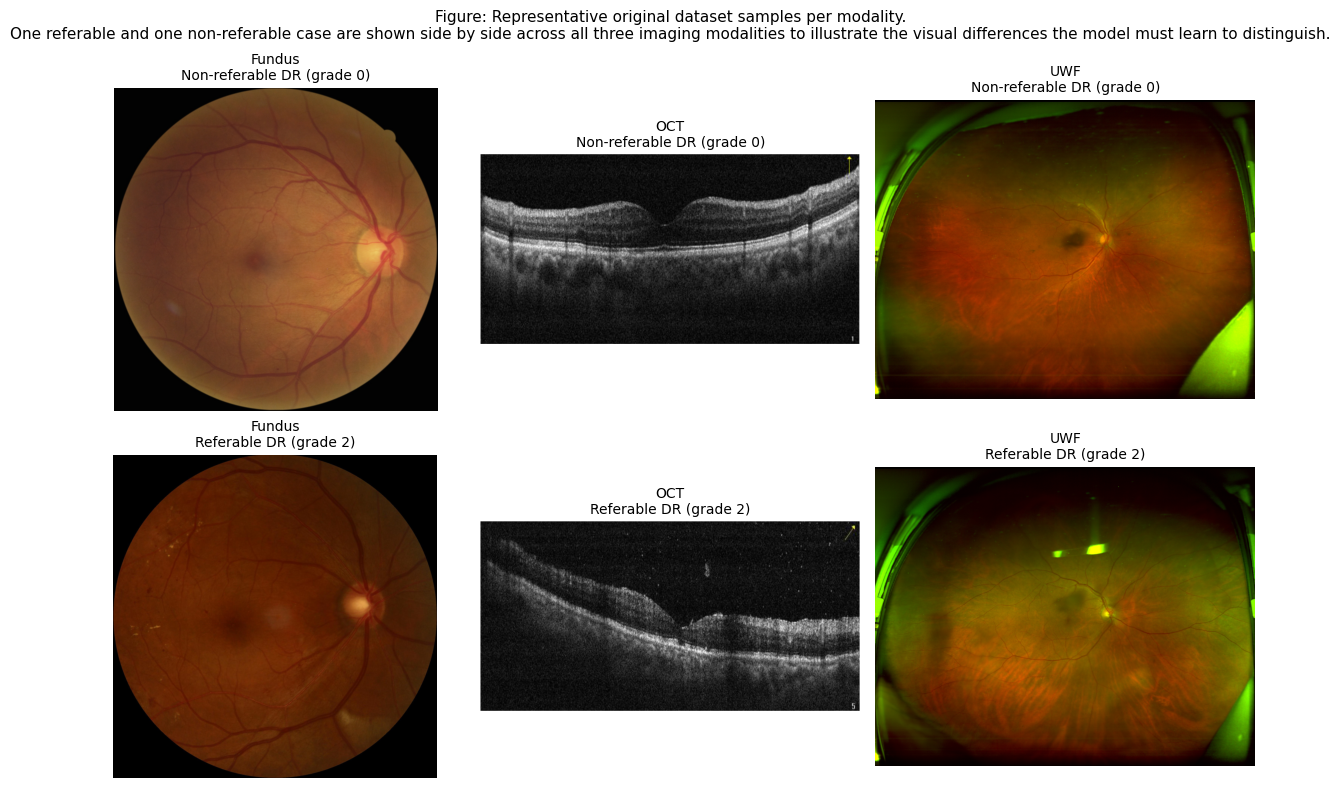

Saved: /content/drive/MyDrive/MMRDR_Project/approved_fast_model_outputs/fig_dataset_samples.png
     sample_id patient_id  dr_grade  referable_dr
781   tr000444   tr000444         0             0
2927  tr001675   tr001675         2             1


In [ ]:
import matplotlib.pyplot as plt

def find_samples_with_all_modalities(frame, n_per_class=1, seed=SEED):
    complete = frame[
        frame["fundus_path"].notna() &
        frame["oct_path"].notna() &
        frame["uwf_path"].notna()
    ]
    samples = []
    for cls in sorted(complete["referable_dr"].unique()):
        subset = complete[complete["referable_dr"] == cls]
        samples.append(subset.sample(n=min(n_per_class, len(subset)), random_state=seed))
    return pd.concat(samples)


modality_cols = [("fundus_path", "Fundus"), ("oct_path", "OCT"), ("uwf_path", "UWF")]

dataset_sample_df = find_samples_with_all_modalities(df, n_per_class=1)

fig, axes = plt.subplots(len(dataset_sample_df), 3, figsize=(12, 4 * len(dataset_sample_df)))
if len(dataset_sample_df) == 1:
    axes = axes.reshape(1, -1)

for row_idx, (_, row) in enumerate(dataset_sample_df.iterrows()):
    label = "Referable DR" if row["referable_dr"] == 1 else "Non-referable DR"
    for col_idx, (path_col, modality_name) in enumerate(modality_cols):
        ax = axes[row_idx, col_idx]
        img = Image.open(row[path_col]).convert("RGB")
        ax.imshow(img)
        ax.set_title(f"{modality_name}\n{label} (grade {row['dr_grade']})", fontsize=10)
        ax.axis("off")

fig.suptitle(
    "Figure: Representative original dataset samples per modality.\n"
    "One referable and one non-referable case are shown side by side across "
    "all three imaging modalities to illustrate the visual differences the "
    "model must learn to distinguish.",
    fontsize=11,
)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_dataset_samples.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", OUTPUT_DIR / "fig_dataset_samples.png")
print(dataset_sample_df[["sample_id", "patient_id", "dr_grade", "referable_dr"]])

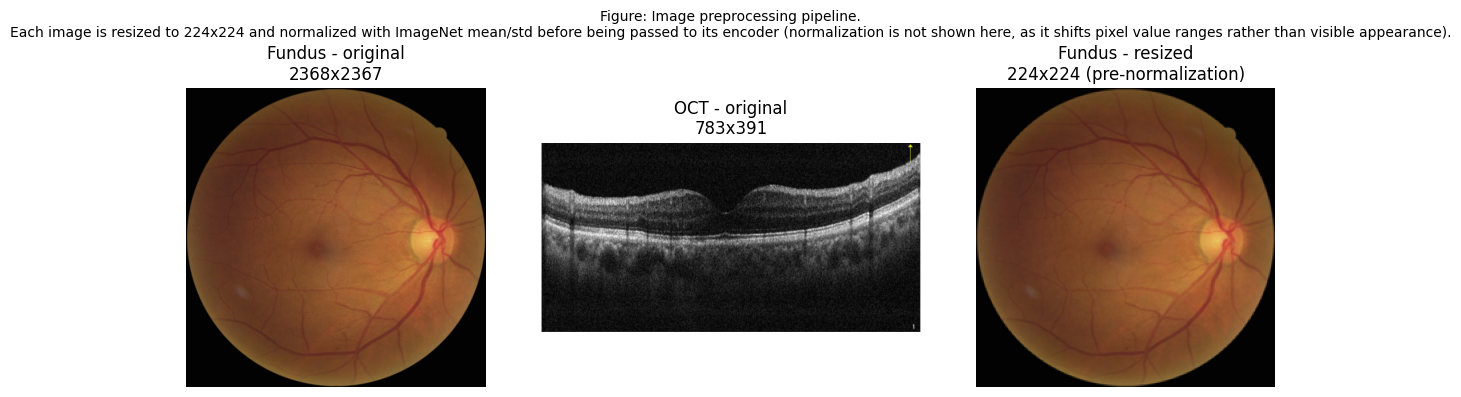

Saved: /content/drive/MyDrive/MMRDR_Project/approved_fast_model_outputs/fig_preprocessing_samples.png

Raw metadata (single sample):
age                            50.4
diabetes_duration               7.8
hba1c                          6.76
systolic_bp                   136.2
diastolic_bp                   73.0
bmi                            19.2
visual_acuity                 0.137
intraocular_pressure           15.4
metadata_is_synthetic             1
gender                         Male
ethnicity                  Hispanic
diabetes_type                Type 2
hypertension                     No
hyperlipidemia                   No
kidney_disease                   No
smoking_status                Never
alcohol_status           Occasional
Name: 781, dtype: object

Transformed metadata vector shape: (30,)
Transformed metadata vector (first 10 values): [-0.428 -0.013 -0.466  0.446 -0.7   -1.608 -0.461 -0.045  0.     0.   ]


In [ ]:
sample_row = dataset_sample_df.iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (path_col, modality_name) in zip(axes[:2], modality_cols[:2]):
    original = Image.open(sample_row[path_col]).convert("RGB")
    ax.imshow(original)
    ax.set_title(f"{modality_name} - original\n{original.size[0]}x{original.size[1]}")
    ax.axis("off")

resized = Image.open(sample_row["fundus_path"]).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
axes[2].imshow(resized)
axes[2].set_title(f"Fundus - resized\n{IMAGE_SIZE}x{IMAGE_SIZE} (pre-normalization)")
axes[2].axis("off")

fig.suptitle(
    "Figure: Image preprocessing pipeline.\n"
    "Each image is resized to 224x224 and normalized with ImageNet mean/std "
    "before being passed to its encoder (normalization is not shown here, as "
    "it shifts pixel value ranges rather than visible appearance).",
    fontsize=10,
)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_preprocessing_samples.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", OUTPUT_DIR / "fig_preprocessing_samples.png")

# Metadata preprocessing example: raw values vs. the transformed vector fed to
# the metadata encoder (median-imputed + standardized numeric columns,
# most-frequent-imputed + one-hot encoded categorical columns).
raw_meta_example = sample_row[numeric_cols + categorical_cols]
transformed_vector = metadata_preprocessor.transform(sample_row.to_frame().T)[0]

print("\nRaw metadata (single sample):")
print(raw_meta_example)
print("\nTransformed metadata vector shape:", transformed_vector.shape)
print("Transformed metadata vector (first 10 values):", np.round(transformed_vector[:10], 3))

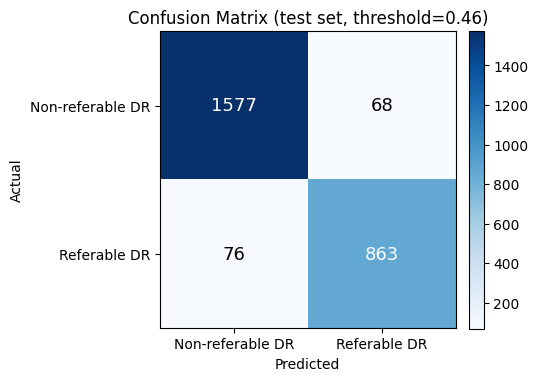

Saved: /content/drive/MyDrive/MMRDR_Project/approved_fast_model_outputs/fig_confusion_matrix.png
[[1577   68]
 [  76  863]]


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred_test)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")

classes = ["Non-referable DR", "Referable DR"]
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes)
ax.set_yticklabels(classes)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix (test set, threshold={best_threshold:.2f})")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]), ha="center", va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13,
        )

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", OUTPUT_DIR / "fig_confusion_matrix.png")
print(cm)

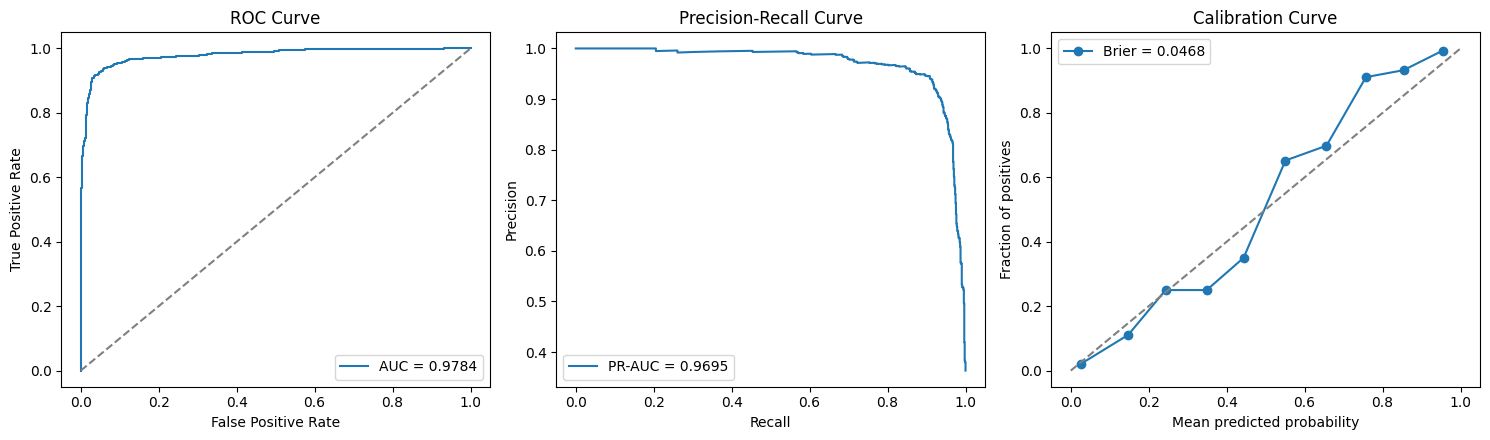

Saved: /content/drive/MyDrive/MMRDR_Project/approved_fast_model_outputs/fig_roc_pr_calibration.png


In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve

fpr, tpr, _ = roc_curve(y_test, p_test[:, 1])
prec, rec, _ = precision_recall_curve(y_test, p_test[:, 1])
frac_pos, mean_pred = calibration_curve(y_test, p_test[:, 1], n_bins=10)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].plot(fpr, tpr, label=f"AUC = {test_m['roc_auc']:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()

axes[1].plot(rec, prec, label=f"PR-AUC = {test_m['pr_auc']:.4f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()

axes[2].plot(mean_pred, frac_pos, marker="o", label=f"Brier = {test_m['brier_score']:.4f}")
axes[2].plot([0, 1], [0, 1], "--", color="gray")
axes[2].set_xlabel("Mean predicted probability")
axes[2].set_ylabel("Fraction of positives")
axes[2].set_title("Calibration Curve")
axes[2].legend()

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_roc_pr_calibration.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", OUTPUT_DIR / "fig_roc_pr_calibration.png")

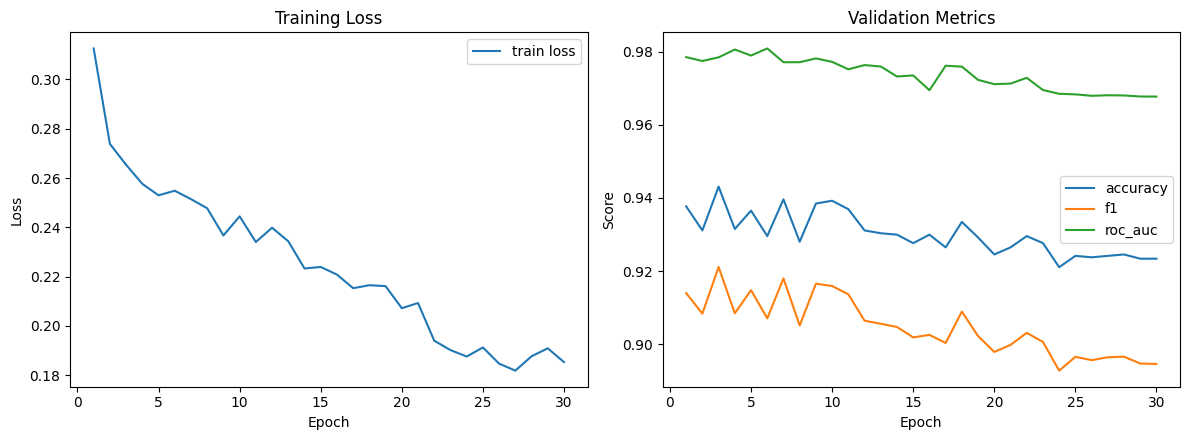

Saved: /content/drive/MyDrive/MMRDR_Project/approved_fast_model_outputs/fig_training_history.png


In [ ]:
history_df = pd.read_csv(OUTPUT_DIR / "approved_fast_attention_gnn_history.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(history_df["epoch"], history_df["loss"], label="train loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training Loss")
axes[0].legend()

for metric in ["accuracy", "f1", "roc_auc"]:
    axes[1].plot(history_df["epoch"], history_df[metric], label=metric)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_title("Validation Metrics")
axes[1].legend()

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_training_history.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", OUTPUT_DIR / "fig_training_history.png")

## Results tables
Writes `paper_results_tables.xlsx` (final metrics, classification report, robustness, gate-weight summary).

In [ ]:
!pip -q install openpyxl

final_metrics_table = pd.DataFrame([test_m]).round(4)
final_metrics_table.index = ["Full modalities (test set)"]

report_dict = classification_report(
    y_test, pred_test,
    target_names=["Non-referable DR", "Referable DR"],
    digits=4, output_dict=True,
)
classification_report_table = pd.DataFrame(report_dict).T.round(4)

gate_summary_table = gate_df.describe().round(4)

print("Table 1: Final test-set metrics (full modalities)")
display(final_metrics_table)

print("\nTable 2: Classification report")
display(classification_report_table)

print("\nTable 3: Modality robustness (test set, one modality dropped at a time)")
display(robustness_df.round(4))

print("\nTable 4: Fusion gate weight summary (test set)")
display(gate_summary_table)

with pd.ExcelWriter(OUTPUT_DIR / "paper_results_tables.xlsx") as writer:
    final_metrics_table.to_excel(writer, sheet_name="final_metrics")
    classification_report_table.to_excel(writer, sheet_name="classification_report")
    robustness_df.round(4).to_excel(writer, sheet_name="modality_robustness", index=False)
    gate_summary_table.to_excel(writer, sheet_name="gate_weights_summary")

print("\nSaved combined tables workbook:", OUTPUT_DIR / "paper_results_tables.xlsx")

Table 1: Final test-set metrics (full modalities)


,accuracy,precision,recall,f1,roc_auc,pr_auc,brier_score
Full modalities (test set),0.9443,0.927,0.9191,0.923,0.9784,0.9695,0.0468



Table 2: Classification report


,precision,recall,f1-score,support
Non-referable DR,0.9540,0.9587,0.9563,1645.0000
Referable DR,0.9270,0.9191,0.9230,939.0000
accuracy,0.9443,0.9443,0.9443,0.9443
macro avg,0.9405,0.9389,0.9397,2584.0000
weighted avg,0.9442,0.9443,0.9442,2584.0000



Table 3: Modality robustness (test set, one modality dropped at a time)


,condition,accuracy,precision,recall,f1,roc_auc,pr_auc,brier_score
0,full_modalities,0.9443,0.9270,0.9191,0.9230,0.9784,0.9695,0.0468
1,fundus_missing,0.7601,0.6337,0.8051,0.7092,0.8366,0.7739,0.1745
2,oct_missing,0.9373,0.9265,0.8988,0.9124,0.9766,0.9665,0.0511
3,uwf_missing,0.8781,0.8451,0.8136,0.8291,0.9410,0.9077,0.0916
4,metadata_missing,0.9156,0.8775,0.8924,0.8849,0.9689,0.9523,0.0648



Table 4: Fusion gate weight summary (test set)


,fundus_gate,oct_gate,uwf_gate,metadata_gate
count,2584.0000,2584.0000,2584.0000,2584.0000
mean,0.6129,0.0259,0.2244,0.1368
std,0.4635,0.1225,0.3536,0.2355
min,0.0000,0.0000,0.0000,0.0000
25%,0.0000,0.0000,0.0000,0.0012
50%,0.9448,0.0000,0.0004,0.0177
75%,0.9966,0.0000,0.4683,0.1529
max,1.0000,0.9913,0.9998,0.9985



Saved combined tables workbook: /content/drive/MyDrive/MMRDR_Project/approved_fast_model_outputs/paper_results_tables.xlsx
